# 02 · Consultas analíticas y figuras

**Entregable 3** · Bases de Datos II · PanTEon Database v1.6.1

Rama: `develop`

---

## Regla de documentación

Para **cada** consulta, la guía (§4.3) exige pregunta, código, resultado e interpretación. En este notebook añadimos además un resumen técnico. Todas las consultas usan la misma configuración de prueba:

```markdown
### Consulta N · <pregunta en una línea>
**Pregunta:** …
**Código:** (celda de agregación)
**Resultado:** (tabla o salida)
**Interpretación:** qué dicen los números, no cómo se obtuvieron.
**Resumen técnico:** cómo se construyó el pipeline y qué optimización se aplicó.
```

## Consultas obligatorias (guía, §4.3)

**Cantidad de elementos**
- [x] 1. TEs por clase, por orden y por superfamilia en toda la base.
- [x] 2. TEs por especie, desglosados por clase, orden y superfamilia.
- [x] 3. Cambio de la cantidad de TEs por clase y orden entre reinos y entre phyla.
- [x] 4. Las 10 especies con más TEs y las 10 con menos.

**Longitud y contenido GC**
- [x] 5. Longitud promedio, mínima y máxima por clase, orden y superfamilia.
- [x] 6. Porcentaje de GC promedio por orden y por reino.
- [x] 7. TEs más largos y más cortos de cada reino (nombre, clasificación, especie).

**Nombres y búsqueda**
- [x] 8. Buscar una secuencia por nombre y mostrar clasificación, especie y taxonomía completa.
- [x] 9. Nombres de todas las secuencias de una superfamilia en una especie dada.

**Generación de bibliotecas** (exportar a `libraries/`, mismo encabezado `>ID#CLASE/ORDEN/SUPERFAMILIA @Especie`)
- [ ] 10. Biblioteca de una especie (especie como parámetro).
- [ ] 11. Biblioteca de un reino (reino como parámetro).

**Relaciones y calidad**
- [ ] 12. Consulta con `$lookup` que una secuencias con la taxonomía de su especie.
- [ ] 13. Comparación por `Source` (Dfam vs. RM2+MCH): especies y secuencias por grupo, promedio de secuencias por especie y longitud promedio de los TEs.
- [ ] 14. Consulta de control de calidad definida por el equipo.

**K-mers**
- [ ] 15. Perfil de *k*-mers de una secuencia dada, para un *k* dado.

## Preguntas propias (mínimo 2)

- [ ] Pregunta 1: …
- [ ] Pregunta 2: …

## Figuras obligatorias (guía, §4.5) — todas leídas desde MongoDB

- [x] Fig. 1 · Barras: composición de TEs por orden en Animalia, Plantae y Fungi.
- [x] Fig. 2 · Boxplot: longitud de los TEs por orden de TE.
- [x] Fig. 3 · Barras o boxplot: contenido GC por reino.
- [x] Fig. 4 · Heatmap: frecuencia promedio de los 16 dinucleótidos (*k*=2) por orden de TE.

> Exportar cada figura a `paper/figures/` en PDF o PNG ≥ 300 dpi.


## Configuración común de las consultas 1–9

La implementación de los pipelines está en `notebooks/consultas_analiticas.py`. Así, las consultas 1–9 utilizan la misma lógica para validar con pocos documentos y para ejecutar el resultado final.

- `MODO_PRUEBA = True`: muestra aleatoria de 5.000 documentos de `sequences`.
- `MODO_PRUEBA = False`: todos los documentos de `sequences`.
- Las consultas 8 y 9 seleccionan parámetros válidos automáticamente en modo prueba.

In [1]:
import pandas as pd

try:
    from consultas_analiticas import (
        conectar, consulta_01, consulta_02, consulta_03, consulta_04,
        consulta_05, consulta_06, consulta_07, consulta_08, consulta_09,
        consulta_15
    )
except ModuleNotFoundError:
    from notebooks.consultas_analiticas import (
        conectar, consulta_01, consulta_02, consulta_03, consulta_04,
        consulta_05, consulta_06, consulta_07, consulta_08, consulta_09,
        consulta_15
    )

cliente_analiticas, db_analiticas = conectar()
TAMANO_MUESTRA = 5000
print("Conectado a panteon_db; tamaño de prueba:", TAMANO_MUESTRA)

Conectado a panteon_db; tamaño de prueba: 5000


## Consulta 1 · Cantidad de TEs por clase, orden y superfamilia

**Pregunta:** ¿Cuántos elementos transponibles hay por clase, por orden y por superfamilia en toda la base?

In [2]:
# Cambiar a True para validar con 5.000 documentos.
MODO_PRUEBA = False
salida_01 = consulta_01(db_analiticas, MODO_PRUEBA, TAMANO_MUESTRA)
tablas_01 = {nombre: pd.DataFrame(filas) for nombre, filas in salida_01["resultado"].items()}
print("Modo:", salida_01["modo"], "| documentos:", salida_01["documentos_analizados"])
for nombre, tabla in tablas_01.items():
    print(f"\n{nombre}: {len(tabla):,} categorías")
    display(tabla)

Modo: BASE COMPLETA | documentos: todos

por_clase: 2 categorías


,cantidad_te,clase
0,194774,CLASSI
1,45172,CLASSII



por_orden: 11 categorías


,cantidad_te,orden
0,119368,LTR
1,68382,LINE
2,36471,TIR
3,5075,HELITRON
4,3634,SINE
5,3456,MITE
6,2933,DIRS
7,344,PLE
8,113,RETROPOSON
9,112,CRYPTON



por_superfamilia: 65 categorías


,cantidad_te,superfamilia
0,50849,COPIA
1,43963,GYPSY
2,23821,L1
3,12202,ERV
4,11234,CR1
...,...,...
60,10,DADA
61,8,U
62,6,GINGER
63,5,PIF


**Resultado e interpretación:** la ejecución completa contó 239.946 secuencias: 194.774 CLASSI (81,17 %) y 45.172 CLASSII (18,83 %). Los órdenes principales fueron LTR (119.368), LINE (68.382) y TIR (36.471); las superfamilias principales fueron COPIA (50.849), GYPSY (43.963), L1 (23.821), ERV (12.202) y CR1 (11.234). LTR, LINE y TIR reúnen aproximadamente el 93,45 % de las secuencias. La biblioteca está dominada por CLASSI, y estos conteos describen su composición, no una abundancia genómica general.

**Resumen técnico:** la consulta usa `$sample` cuando `MODO_PRUEBA=True`, proyecta únicamente los tres campos de clasificación y usa `$facet` para ejecutar tres agrupaciones en paralelo. `$group` con `$sum: 1` cuenta secuencias y `allowDiskUse=True` ayuda a ejecutar la versión completa sin cargar el campo pesado `secuencia`.

## Consulta 2 · TEs por especie y clasificación

**Pregunta:** ¿Cuántos TEs tiene cada especie, desglosados por clase, orden y superfamilia?

In [3]:
# Cambiar a True para validar con 5.000 documentos.
MODO_PRUEBA = False
salida_02 = consulta_02(db_analiticas, MODO_PRUEBA, TAMANO_MUESTRA)
tablas_02 = {nombre: pd.DataFrame(filas) for nombre, filas in salida_02["resultado"].items()}
print("Modo:", salida_02["modo"], "| documentos:", salida_02["documentos_analizados"])
for nombre, tabla in tablas_02.items():
    print(f"\n{nombre}: {len(tabla):,} combinaciones")
    display(tabla.head(20))

Modo: BASE COMPLETA | documentos: todos

por_clase: 4,642 combinaciones


,cantidad_te,especie,clase
0,1280,Malus domestica,CLASSI
1,1056,Geotrypetes seraphini,CLASSI
2,1055,Blumeria graminis f sp tritici,CLASSI
3,1052,Nicotiana attenuata,CLASSI
4,972,Callithrix jacchus,CLASSI
5,851,Homininae,CLASSI
6,848,Nelumbo lutea,CLASSI
7,825,Colobus angolensis,CLASSI
8,807,Chlorocebus sabaeus,CLASSI
9,769,Anastrepha obliqua,CLASSI



por_orden: 8,862 combinaciones


,cantidad_te,especie,orden
0,1182,Malus domestica,LTR
1,995,Nicotiana attenuata,LTR
2,931,Geotrypetes seraphini,LINE
3,759,Callithrix jacchus,LTR
4,702,Malus sieversii,LTR
5,697,Nelumbo lutea,LTR
6,684,Anastrepha obliqua,LINE
7,637,Danio rerio,TIR
8,636,Solanum stenotomum,LTR
9,610,Homininae,LTR



por_superfamilia: 18,513 combinaciones


,cantidad_te,especie,superfamilia
0,718,Callithrix jacchus,ERV
1,671,Malus domestica,COPIA
2,574,Nicotiana attenuata,COPIA
3,569,Homininae,ERV
4,568,Nelumbo lutea,COPIA
5,559,Colobus angolensis,ERV
6,544,Chlorocebus sabaeus,ERV
7,427,Geotrypetes seraphini,L2
8,406,Eucalyptus globulus,COPIA
9,401,Linum usitatissimum,COPIA


**Resultado e interpretación:** la versión completa produjo 4.642 combinaciones especie–clase, 8.862 especie–orden y 18.513 especie–superfamilia. Las mayores concentraciones fueron Malus domestica/CLASSI (1.280), Malus domestica/LTR (1.182) y Callithrix jacchus/ERV (718). Las tablas completas quedan en `tablas_02`; la celda muestra las primeras 20 filas para no saturar el notebook.

**Resumen técnico:** se proyectan solo `especie` y los tres niveles de `te_classification`; después `$facet` ejecuta tres `$group` independientes con la especie incluida en la clave. `$sum: 1` cuenta documentos, y `$sort` prioriza las combinaciones más abundantes. `$sample` reduce el costo durante la validación; `allowDiskUse=True` mantiene la consulta escalable.

## Consulta 3 · Comparación entre reinos y phyla

**Pregunta:** ¿Cómo cambia la cantidad de TEs por clase y orden entre los reinos y entre los phyla?

In [4]:
MODO_PRUEBA = False
salida_03 = consulta_03(db_analiticas, MODO_PRUEBA, TAMANO_MUESTRA)
tablas_03 = {nombre: pd.DataFrame(filas) for nombre, filas in salida_03["resultado"].items()}
print("Modo:", salida_03["modo"], "| documentos:", salida_03["documentos_analizados"])
for nombre, tabla in tablas_03.items():
    print(f"\n{nombre}: {len(tabla):,} combinaciones")
    display(tabla)

Modo: BASE COMPLETA | documentos: todos

por_reino: 27 combinaciones


,cantidad_te,kingdom,clase,orden
0,44477,Animalia,CLASSI,LINE
1,25382,Animalia,CLASSI,LTR
2,21659,Animalia,CLASSII,TIR
3,3091,Animalia,CLASSI,SINE
4,2718,Animalia,CLASSII,MITE
5,2125,Animalia,CLASSI,DIRS
6,1167,Animalia,CLASSII,HELITRON
7,257,Animalia,CLASSI,PLE
8,113,Animalia,CLASSI,RETROPOSON
9,112,Animalia,CLASSII,CRYPTON



por_phylum: 188 combinaciones


,cantidad_te,phylum,clase,orden
0,1,Acanthocephala,CLASSI,PLE
1,84523,Angiosperma,CLASSI,LTR
2,17265,Angiosperma,CLASSI,LINE
3,11407,Angiosperma,CLASSII,TIR
4,2144,Angiosperma,CLASSII,HELITRON
...,...,...,...,...
183,23,Zoopagomycota,CLASSII,TIR
184,13,Zoopagomycota,CLASSI,DIRS
185,10,Zoopagomycota,CLASSII,HELITRON
186,1,Zoopagomycota,CLASSI,SINE


**Resultado e interpretación:** la versión completa produjo 27 combinaciones por reino y 188 por phylum. En Animalia predominan CLASSI/LINE (44.477), CLASSI/LTR (25.382) y CLASSII/TIR (21.659); en Fungi, CLASSI/LTR (7.937); y en Plantae, CLASSI/LTR (86.049). Por phylum, los mayores grupos corresponden a Angiosperma, Chordata y Arthropoda. El `$trim` aplicado al phylum evita separar categorías por espacios iniciales presentes en algunos metadatos.

**Resumen técnico:** se usa `$lookup` desde `sequences.species_id` hacia `species._id` para recuperar `taxonomy.phylum`; el reino se aprovecha desde la referencia extendida de `sequences`. Tras `$unwind` y `$project`, `$facet` calcula las tablas por reino y phylum en una sola agregación.

## Consulta 4 · Especies con más y menos TEs

**Pregunta:** ¿Cuáles son las 10 especies con más TEs y las 10 con menos?

In [5]:
MODO_PRUEBA = False
salida_04 = consulta_04(db_analiticas, MODO_PRUEBA, TAMANO_MUESTRA)
tablas_04 = {nombre: pd.DataFrame(filas) for nombre, filas in salida_04["resultado"].items()}
print("Modo:", salida_04["modo"], "| documentos:", salida_04["documentos_analizados"])
print("\n10 especies con más TEs")
display(tablas_04["mas_te"])
print("10 especies con menos TEs")
display(tablas_04["menos_te"])

Modo: BASE COMPLETA | documentos: todos

10 especies con más TEs


,cantidad_te,especie
0,1627,Malus domestica
1,1352,Danio rerio
2,1294,Callithrix jacchus
3,1173,Homininae
4,1159,Nicotiana attenuata
5,1148,Colobus angolensis
6,1129,Chlorocebus sabaeus
7,1115,Geotrypetes seraphini
8,1103,Sitophilus oryzae
9,1090,Oryza sativa


10 especies con menos TEs


,cantidad_te,especie
0,1,Abortiporus biennis
1,1,Absidia glauca
2,1,Achaetomium macrosporum
3,1,Acidothrix acidophila
4,1,Acropora acuminata
5,1,Acropora nasuta
6,1,Agrocybe aegerita
7,1,Alternaria arborescens
8,1,Alternaria carthami
9,1,Alternaria gaisen


**Resultado e interpretación:** en la base completa, las especies con más TEs fueron Malus domestica (1.627), Danio rerio (1.352), Callithrix jacchus (1.294), Homininae (1.173) y Nicotiana attenuata (1.159). En el extremo inferior hay numerosas especies con una sola secuencia; el ranking muestra las diez primeras alfabéticamente. Si hay empates en el décimo puesto, el desempate determinista es por `especie`.

**Resumen técnico:** `$group` suma una unidad por cada documento de `sequences` y obtiene el total por especie. `$facet` mantiene en paralelo dos ordenamientos: descendente para las diez mayores y ascendente para las diez menores; `$limit` devuelve solo el ranking solicitado.

## Consulta 5 · Longitud por clase, orden y superfamilia

**Pregunta:** ¿Cuál es la longitud promedio, mínima y máxima de los TEs por clase, orden y superfamilia?

In [6]:
MODO_PRUEBA = False
salida_05 = consulta_05(db_analiticas, MODO_PRUEBA, TAMANO_MUESTRA)
tablas_05 = {nombre: pd.DataFrame(filas) for nombre, filas in salida_05["resultado"].items()}
print("Modo:", salida_05["modo"], "| documentos:", salida_05["documentos_analizados"])
for nombre, tabla in tablas_05.items():
    tabla["promedio_longitud"] = tabla["promedio_longitud"].round(2)
    print(f"\n{nombre}")
    display(tabla)

Modo: BASE COMPLETA | documentos: todos

por_clase


,promedio_longitud,longitud_minima,longitud_maxima,cantidad_te,clase
0,4453.15,81,19926,194774,CLASSI
1,2137.25,100,18485,45172,CLASSII



por_orden


,promedio_longitud,longitud_minima,longitud_maxima,cantidad_te,orden
0,6395.48,173,18485,58,MAVERICK
1,5285.58,100,19926,119368,LTR
2,4413.54,109,6998,2933,DIRS
3,4094.59,100,14819,5075,HELITRON
4,3241.44,500,6000,68382,LINE
5,2211.62,107,8809,344,PLE
6,2034.46,100,9991,36471,TIR
7,1290.97,195,3463,113,RETROPOSON
8,335.72,100,500,3456,MITE
9,303.43,108,2367,112,CRYPTON



por_superfamilia


,promedio_longitud,longitud_minima,longitud_maxima,cantidad_te,superfamilia
0,7316.41,177,19135,2962,CAULIMOVIRUS
1,6781.80,331,18849,1995,BELPAO
2,6400.80,2401,9528,10,DADA
3,6395.48,173,18485,58,MAVERICK
4,6312.36,2502,14774,4588,LARD
...,...,...,...,...,...
60,229.27,101,392,346,MIR
61,223.75,143,381,8,U
62,203.75,136,373,68,B2
63,162.62,81,376,126,ID


**Resultado e interpretación:** CLASSI presentó una longitud promedio de 4.453,15 bases, con mínimo de 81 y máximo de 19.926; CLASSII promedió 2.137,25 bases, con mínimo de 100 y máximo de 18.485. Por orden, MAVERICK tuvo el promedio más alto (6.395,48), aunque solo contiene 58 secuencias, seguido de LTR (5.285,58). Por superfamilia, CAULIMOVIRUS alcanzó 7.316,41 bases de promedio. La media se interpreta junto con los extremos y el tamaño de cada grupo.

**Resumen técnico:** se proyecta `metrics.longitud` y cada nivel de clasificación. Tres ramas de `$facet` aplican `$group` con `$avg`, `$min`, `$max` y `$sum`; no se trae el campo `secuencia`, reduciendo memoria y transferencia.

## Consulta 6 · Contenido GC por orden y reino

**Pregunta:** ¿Cuál es el porcentaje de GC promedio de los TEs por orden y por reino?

In [7]:
MODO_PRUEBA = False
salida_06 = consulta_06(db_analiticas, MODO_PRUEBA, TAMANO_MUESTRA)
tablas_06 = {nombre: pd.DataFrame(filas) for nombre, filas in salida_06["resultado"].items()}
for nombre, tabla in tablas_06.items():
    tabla["promedio_pct_gc"] = tabla["promedio_pct_gc"].round(3)
    print(f"\n{nombre}")
    display(tabla)


por_orden


,promedio_pct_gc,cantidad_te,orden
0,52.972,3634,SINE
1,52.595,2933,DIRS
2,50.689,113,RETROPOSON
3,45.158,112,CRYPTON
4,44.429,344,PLE
5,43.809,68382,LINE
6,42.813,119368,LTR
7,41.473,3456,MITE
8,41.038,5075,HELITRON
9,40.818,36471,TIR



por_reino


,promedio_pct_gc,cantidad_te,kingdom
0,46.173,19797,Fungi
1,44.479,101144,Animalia
2,41.249,119005,Plantae


**Resultado e interpretación:** por reino, Fungi presentó el mayor GC promedio (46,173 %), seguido de Animalia (44,479 %) y Plantae (41,249 %). Por orden, SINE tuvo el promedio más alto (52,972 %) y MAVERICK el más bajo (40,151 %). Las tablas también muestran el número de secuencias de cada grupo para evitar interpretar del mismo modo categorías con tamaños muy diferentes.

**Resumen técnico:** se proyectan únicamente `kingdom`, `orden_fasta` y `metrics.pct_gc`; `$facet` calcula dos `$group` con `$avg` y `$sum`. El promedio es no ponderado por secuencia: una secuencia larga no domina automáticamente el promedio.

## Consulta 7 · TEs extremos por reino

**Pregunta:** ¿Cuál es el TE más largo y el más corto de cada reino, mostrando nombre, clasificación y especie?

In [8]:
MODO_PRUEBA = False
salida_07 = consulta_07(db_analiticas, MODO_PRUEBA, TAMANO_MUESTRA)
tablas_07 = {nombre: pd.DataFrame(filas) for nombre, filas in salida_07["resultado"].items()}
print("Más largos por reino")
display(tablas_07["mas_largos"])
print("Más cortos por reino")
display(tablas_07["mas_cortos"])

Más largos por reino


,id_seq,especie,kingdom,clase,orden,superfamilia,longitud
0,PDB00076912,Aphelocoma californica,Animalia,CLASSI,LTR,ERV,18951
1,PDB00194372,Lactarius subdulcis,Fungi,CLASSI,LTR,ERV,19189
2,PDB00038441,Helianthus annuus,Plantae,CLASSI,LTR,GYPSY,19926


Más cortos por reino


,id_seq,especie,kingdom,clase,orden,superfamilia,longitud
0,AllBul-4.608,Orientallactaga bullata,Animalia,CLASSI,SINE,ID,81
1,PDB00183015,Dactylonectria macrodidyma,Fungi,CLASSII,HELITRON,HELITRON,100
2,PDB00049072,Oryza barthii,Plantae,CLASSII,HELITRON,HELITRON,100


**Resultado e interpretación:** los TEs más largos fueron PDB00076912 en Animalia (18.951 bases), PDB00194372 en Fungi (19.189) y PDB00038441 en Plantae (19.926). Los más cortos fueron AllBul-4.608 en Animalia (81 bases), PDB00183015 en Fungi (100) y PDB00049072 en Plantae (100). En caso de empate se selecciona el `id_seq` alfabéticamente para que el resultado sea reproducible.

**Resumen técnico:** se proyectan el identificador, especie, reino, clasificación y longitud. Dentro de cada rama de `$facet`, `$sort` ordena por reino y longitud; `$group` con `$first` conserva el extremo de cada reino y `$replaceWith` devuelve el registro completo.

## Consulta 8 · Búsqueda de una secuencia por nombre

**Pregunta:** Dado el nombre de una secuencia, ¿cuál es su clasificación, especie y taxonomía completa?

In [9]:
MODO_PRUEBA = False
NOMBRE_SECUENCIA = None if MODO_PRUEBA else "PDB00000001"
salida_08 = consulta_08(db_analiticas, MODO_PRUEBA, TAMANO_MUESTRA, NOMBRE_SECUENCIA)
print("Modo:", salida_08["modo"], "| nombre buscado:", salida_08["resultado"]["nombre_secuencia"])
display(pd.DataFrame(salida_08["resultado"]["registros"]))

Modo: BASE COMPLETA | nombre buscado: PDB00000001


,id_seq,especie,te_classification,taxonomy
0,PDB00000001,Halicephalobus mephisto,"{'clase_fasta': 'CLASSII', 'orden_fasta': 'HEL...","{'kingdom': 'Animalia', 'phylum': 'Nematoda', ..."


**Resultado e interpretación:** la búsqueda de `PDB00000001` devolvió una coincidencia: pertenece a `Halicephalobus mephisto`, es `CLASSII/HELITRON/HELITRON` y su taxonomía corresponde a Animalia, Nematoda, Chromadorea, Rhabditida y Panagrolaimidae. El parámetro se puede sustituir por cualquier valor de `id_seq`.

**Resumen técnico:** `$match` filtra por `id_seq` y `$lookup` une la referencia `species_id` con `species._id`; `$unwind` elimina la envoltura de la coincidencia y `$project` devuelve únicamente la información solicitada. En modo prueba se escoge automáticamente un identificador real de una muestra de 5.000.

## Consulta 9 · Secuencias de una superfamilia en una especie

**Pregunta:** ¿Cuáles son los nombres de todas las secuencias de una superfamilia dada dentro de una especie dada?

In [10]:
MODO_PRUEBA = False
ESPECIE_OBJETIVO = None if MODO_PRUEBA else "Puma concolor"
SUPERFAMILIA_OBJETIVO = None if MODO_PRUEBA else "TRNA"
salida_09 = consulta_09(
    db_analiticas, MODO_PRUEBA, TAMANO_MUESTRA,
    ESPECIE_OBJETIVO, SUPERFAMILIA_OBJETIVO
)
parametros_09 = salida_09["resultado"]
print("Modo:", salida_09["modo"])
print("Especie:", parametros_09["especie"], "| superfamilia:", parametros_09["superfamilia"])
display(pd.DataFrame(parametros_09["secuencias"]))

Modo: BASE COMPLETA
Especie: Puma concolor | superfamilia: TRNA


,id_seq,especie,superfamilia
0,PumCon-1.11,Puma concolor,TRNA
1,PumCon-1.14,Puma concolor,TRNA
2,PumCon-1.16,Puma concolor,TRNA
3,PumCon-1.25,Puma concolor,TRNA
4,PumCon-1.28,Puma concolor,TRNA
5,PumCon-1.30,Puma concolor,TRNA
6,PumCon-1.34,Puma concolor,TRNA


**Resultado e interpretación:** para `Puma concolor` y la superfamilia `TRNA` se encontraron 7 secuencias: `PumCon-1.11`, `PumCon-1.14`, `PumCon-1.16`, `PumCon-1.25`, `PumCon-1.28`, `PumCon-1.30` y `PumCon-1.34`. Ambos parámetros se pueden sustituir; en modo prueba se elige una pareja especie–superfamilia presente en la muestra.

**Resumen técnico:** `$match` combina igualdad en `especie` y `te_classification.superfamilia_fasta`; `$project` devuelve `id_seq` y `$sort` ordena los nombres. La consulta usa los campos desnormalizados para evitar un `$lookup` cuando la búsqueda no necesita taxonomía adicional.

## Consulta 15 · Perfil de k-mers de una secuencia

**Pregunta:** ¿Cuál es el perfil de k-mers de una secuencia dada, para un tamaño *k* específico?

In [6]:
MODO_PRUEBA = False
ID_SEQ_BUSCADO = "PDB00000001" # Cualquier ID de secuencia (id_seq en mongo)
K_BUSCADO = 6

salida_15 = consulta_15(
    db_analiticas, MODO_PRUEBA, TAMANO_MUESTRA, 
    ID_SEQ_BUSCADO, K_BUSCADO
)

parametros_15 = salida_15["resultado"]
print("Modo:", salida_15["modo"])
print(f"Secuencia: {parametros_15['id_seq']} | k: {parametros_15['k']}")

if parametros_15["perfil"]:
    doc_perfil = parametros_15["perfil"][0]
    print(f"Ventanas válidas (sin 'N'): {doc_perfil.get('valid_windows', 0):,}")
    
    df_counts = pd.DataFrame(
        list(doc_perfil["counts"].items()), 
        columns=["k-mer", "frecuencia"]
    )
    df_counts = df_counts.sort_values(by="frecuencia", ascending=False).reset_index(drop=True)
    
    print(f"Total de k-mers únicos encontrados: {len(df_counts):,}")
    display(df_counts.head(20))
else:
    print("No se encontró el perfil de k-mers para esos parámetros.")

Modo: BASE COMPLETA
Secuencia: PDB00000001 | k: 6
Ventanas válidas (sin 'N'): 1,986
Total de k-mers únicos encontrados: 1,253


,k-mer,frecuencia
0,AAAAAA,18
1,TTTAAA,15
2,AAAAAT,14
3,TTTTAA,14
4,AAATTT,13
5,TTAAAA,13
6,AAAATT,11
7,TAAAAA,11
8,AATTTT,9
9,ATTTTA,8


**Resultado e interpretación:**
Como se ve en la tabla para la secuencia `PDB00000001` (con $k=6$), las frecuencias están súper dominadas por adenina (A) y timina (T). El k-mer que más aparece es `AAAAAA` con 18 repeticiones, seguido de `TTTAAA` (15) y `AAAAAT` (14). Si miramos el top 20, casi todos los motivos son puras combinaciones de A y T, y raras veces se asoma una citosina (como en `TCAAAA`, que sale 6 veces). Esto básicamente nos dice que la secuencia es muy rica en AT (o sea, tiene bajo contenido de GC), algo que tiene mucho sentido y es típico en la estructura de los elementos transponibles.

**Resumen técnico:**
Para que la consulta no se demore, filtramos directo con un `$match` que aprovecha el índice compuesto `[id_seq, k]` que ya teníamos en la colección `kmers`. Después, con un `$project` nos quedamos solo con el subdocumento `counts` y dejamos por fuera el `_id` y otros metadatos para no cargar cosas pesadas sin necesidad. Finalmente, la magia visual se hace del lado de Python: sacamos las llaves y valores del diccionario, los metemos en un DataFrame de Pandas y le aplicamos un `sort_values` de mayor a menor para tabular los k-mers más repetidos de forma clara.

## Sección de visualización de datos

Las cuatro figuras obligatorias se generan directamente desde MongoDB mediante pipelines de agregación. El notebook puede ejecutarse primero con una muestra aleatoria de 5.000 documentos y después con la base completa. Las figuras finales se exportan en PNG a 300 dpi y en PDF vectorial dentro de `paper/figures/`.

La extracción está implementada en `notebooks/visualizaciones.py`; aquí se documentan las transformaciones, se construyen las figuras con `matplotlib`/`seaborn` y se muestran las tablas que respaldan cada gráfico.

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

try:
    from visualizaciones import (
        DINUCLEOTIDOS, ORDENES_FIGURAS, REINOS_FIGURAS,
        figura_01_composicion, figura_02_longitud, figura_03_gc,
        figura_04_dinucleotidos,
    )
except ModuleNotFoundError:
    from notebooks.visualizaciones import (
        DINUCLEOTIDOS, ORDENES_FIGURAS, REINOS_FIGURAS,
        figura_01_composicion, figura_02_longitud, figura_03_gc,
        figura_04_dinucleotidos,
    )

# Cambiar a True para validar rápidamente con 5.000 documentos.
MODO_PRUEBA_FIGURAS = False
TAMANO_MUESTRA_FIGURAS = 5000

# Permite ejecutar el notebook desde la raíz del repositorio o desde notebooks/.
RUTA_FIGURAS = Path("paper/figures")
if not RUTA_FIGURAS.exists():
    RUTA_FIGURAS = Path("../paper/figures")
RUTA_FIGURAS.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")

def guardar_figura(figura, nombre):
    """Guarda cada figura en PNG de 300 dpi y PDF vectorial."""
    rutas = {
        "png": RUTA_FIGURAS / f"{nombre}.png",
        "pdf": RUTA_FIGURAS / f"{nombre}.pdf",
    }
    figura.savefig(rutas["png"], dpi=300, bbox_inches="tight")
    figura.savefig(rutas["pdf"], bbox_inches="tight")
    return rutas

print("Modo de visualización:", "MUESTRA" if MODO_PRUEBA_FIGURAS else "BASE COMPLETA")
print("Directorio de salida:", RUTA_FIGURAS.resolve())

Modo de visualización: BASE COMPLETA
Directorio de salida: C:\Users\Usuario\OneDrive\Desktop\panteon-mongodb-bd2\paper\figures


### Figura 1 · Composición de TEs por orden y reino

**Pregunta:** ¿Cómo se distribuyen los órdenes de elementos transponibles en Animalia, Plantae y Fungi?

El pipeline agrupa los documentos de `sequences` por `kingdom` y `te_classification.orden_fasta`. La figura utiliza barras apiladas para conservar simultáneamente el número total de secuencias y la contribución de cada orden.

Modo: BASE COMPLETA | filas agrupadas: 27


,cantidad_te,reino,orden
0,44477,Animalia,LINE
1,25382,Animalia,LTR
2,21659,Animalia,TIR
3,3091,Animalia,SINE
4,2718,Animalia,MITE
5,2125,Animalia,DIRS
6,1167,Animalia,HELITRON
7,257,Animalia,PLE
8,113,Animalia,RETROPOSON
9,112,Animalia,CRYPTON


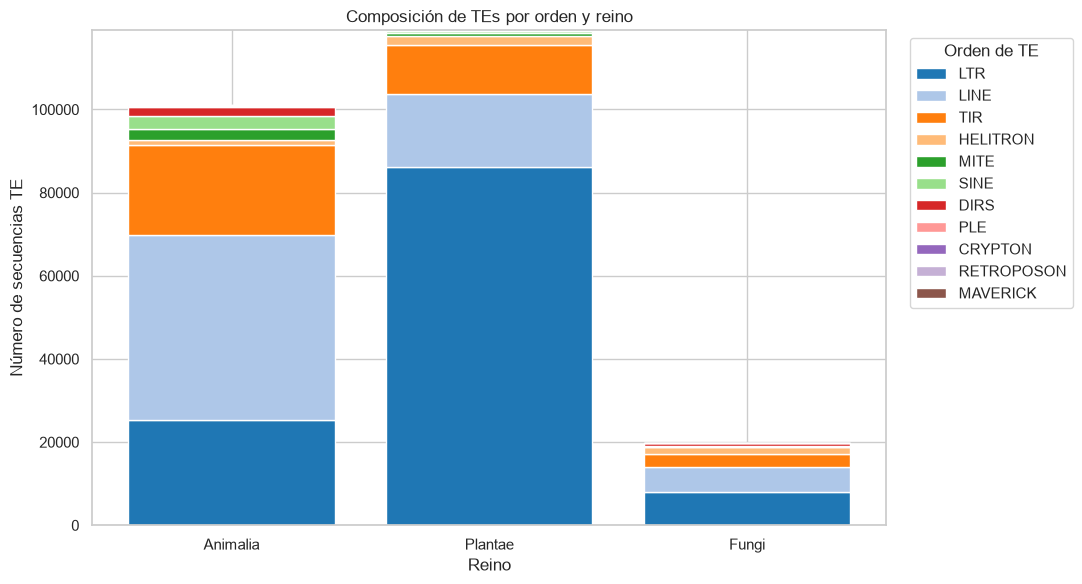

In [12]:
salida_figura_01 = figura_01_composicion(
    db_analiticas, MODO_PRUEBA_FIGURAS, TAMANO_MUESTRA_FIGURAS
)
datos_figura_01 = pd.DataFrame(salida_figura_01["datos"])
tabla_figura_01 = datos_figura_01.sort_values(
    ["reino", "cantidad_te"], ascending=[True, False]
)
pivot_figura_01 = (
    datos_figura_01.pivot_table(
        index="reino", columns="orden", values="cantidad_te",
        aggfunc="sum", fill_value=0
    )
    .reindex(index=REINOS_FIGURAS, columns=ORDENES_FIGURAS, fill_value=0)
)

figura_01, ax = plt.subplots(figsize=(11, 6))
posiciones = np.arange(len(pivot_figura_01.index))
base = np.zeros(len(pivot_figura_01.index))
colores = sns.color_palette("tab20", n_colors=len(ORDENES_FIGURAS))

for orden, color in zip(ORDENES_FIGURAS, colores):
    valores = pivot_figura_01[orden].to_numpy(dtype=float)
    ax.bar(posiciones, valores, bottom=base, label=orden, color=color)
    base += valores

ax.set_xticks(posiciones, pivot_figura_01.index)
ax.set_ylabel("Número de secuencias TE")
ax.set_xlabel("Reino")
ax.set_title("Composición de TEs por orden y reino")
ax.legend(title="Orden de TE", bbox_to_anchor=(1.02, 1), loc="upper left")
figura_01.tight_layout()
rutas_figura_01 = guardar_figura(figura_01, "figura_1_composicion_orden_reino")

print("Modo:", salida_figura_01["modo"], "| filas agrupadas:", len(tabla_figura_01))
display(tabla_figura_01)
display(figura_01)
plt.close(figura_01)

**Interpretación:** en la ejecución completa, Plantae concentra el mayor número de registros y está dominada por LTR; Animalia presenta principalmente LINE, LTR y TIR; Fungi muestra una combinación menor, también encabezada por LTR y LINE. Las diferencias de altura reflejan tanto la composición de órdenes como el tamaño desigual de las bibliotecas por reino.

### Figura 2 · Longitud de los TEs por orden

**Pregunta:** ¿Cómo varía la distribución de longitudes entre los órdenes de TEs?

El pipeline devuelve la longitud de cada secuencia junto con su orden. El boxplot muestra mediana y rango intercuartílico; se ocultan los puntos extremos para mantener la legibilidad y se usa escala logarítmica porque los órdenes abarcan longitudes muy diferentes.

Modo: BASE COMPLETA | secuencias graficadas: 239946


,cantidad_te,mediana,promedio,minimo,maximo
orden,,,,,
MAVERICK,58,6758.0,6395.482759,173,18485
LTR,119368,5347.0,5285.582107,100,19926
DIRS,2933,5143.0,4413.542107,109,6998
HELITRON,5075,3371.0,4094.586798,100,14819
LINE,68382,3279.0,3241.435802,500,6000
PLE,344,2208.5,2211.622093,107,8809
TIR,36471,1341.0,2034.462395,100,9991
RETROPOSON,113,1159.0,1290.973451,195,3463
MITE,3456,345.5,335.716435,100,500


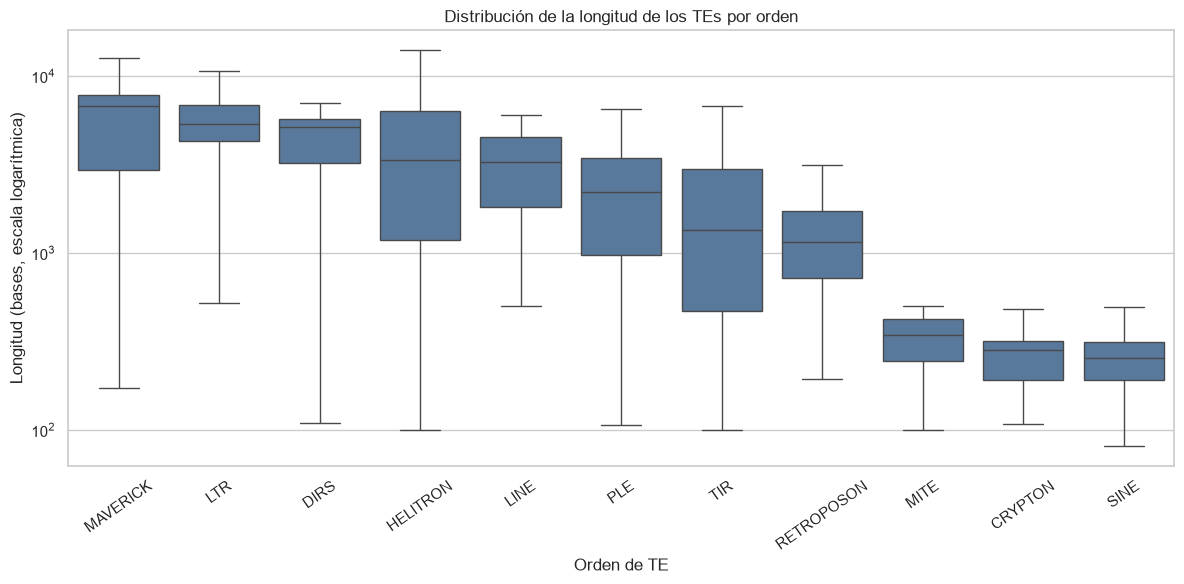

In [13]:
salida_figura_02 = figura_02_longitud(
    db_analiticas, MODO_PRUEBA_FIGURAS, TAMANO_MUESTRA_FIGURAS
)
datos_figura_02 = pd.DataFrame(salida_figura_02["datos"])
ordenes_boxplot = (
    datos_figura_02.groupby("orden")["longitud"]
    .median().sort_values(ascending=False).index.tolist()
)
tabla_figura_02 = (
    datos_figura_02.groupby("orden")["longitud"]
    .agg(cantidad_te="size", mediana="median", promedio="mean",
         minimo="min", maximo="max")
    .reindex(ordenes_boxplot)
)

figura_02, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(
    data=datos_figura_02, x="orden", y="longitud",
    order=ordenes_boxplot, showfliers=False, color="#4C78A8", ax=ax
)
ax.set_yscale("log")
ax.set_xlabel("Orden de TE")
ax.set_ylabel("Longitud (bases, escala logarítmica)")
ax.set_title("Distribución de la longitud de los TEs por orden")
ax.tick_params(axis="x", rotation=35)
figura_02.tight_layout()
rutas_figura_02 = guardar_figura(figura_02, "figura_2_longitud_por_orden")

print("Modo:", salida_figura_02["modo"], "| secuencias graficadas:", len(datos_figura_02))
display(tabla_figura_02)
display(figura_02)
plt.close(figura_02)

**Interpretación:** los órdenes LTR y MAVERICK presentan las longitudes centrales más elevadas, mientras que MITE y SINE se concentran en longitudes mucho menores. La escala logarítmica permite comparar los grupos sin que los órdenes largos oculten la variabilidad de los elementos cortos.

### Figura 3 · Contenido GC promedio por reino

**Pregunta:** ¿Qué contenido GC promedio presentan los TEs de cada reino?

El pipeline calcula en MongoDB el promedio, la desviación estándar poblacional y el número de secuencias por reino. Las barras representan el promedio y las barras de error muestran la desviación estándar.

Modo: BASE COMPLETA


,reino,promedio_pct_gc,desviacion_pct_gc,cantidad_te
0,Animalia,44.478642,8.045964,101144
1,Plantae,41.249384,6.332086,119005
2,Fungi,46.172834,8.775874,19797


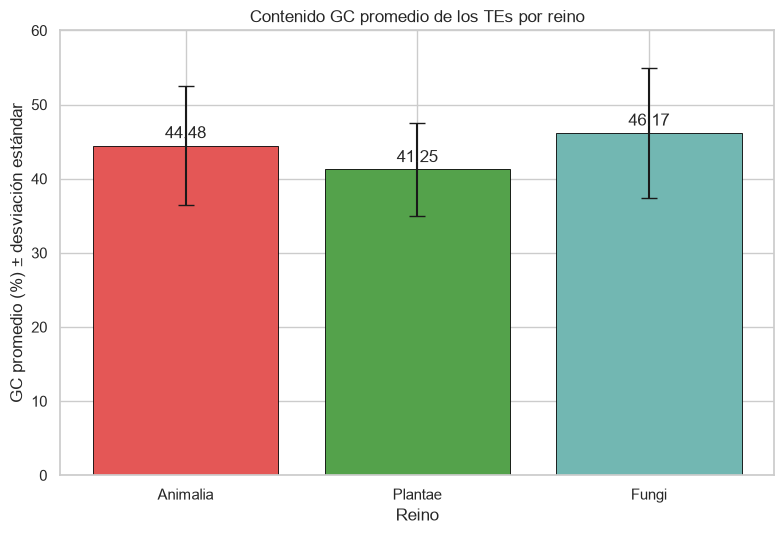

In [14]:
salida_figura_03 = figura_03_gc(
    db_analiticas, MODO_PRUEBA_FIGURAS, TAMANO_MUESTRA_FIGURAS
)
tabla_figura_03 = (
    pd.DataFrame(salida_figura_03["datos"])
    .set_index("reino")
    .reindex(REINOS_FIGURAS)
    .reset_index()
)

figura_03, ax = plt.subplots(figsize=(8, 5.5))
posiciones = np.arange(len(tabla_figura_03))
ax.bar(
    posiciones, tabla_figura_03["promedio_pct_gc"],
    yerr=tabla_figura_03["desviacion_pct_gc"],
    capsize=6, color=["#E45756", "#54A24B", "#72B7B2"],
    edgecolor="black", linewidth=0.6
)
ax.set_xticks(posiciones, tabla_figura_03["reino"])
ax.set_ylim(0, 60)
ax.set_xlabel("Reino")
ax.set_ylabel("GC promedio (%) ± desviación estándar")
ax.set_title("Contenido GC promedio de los TEs por reino")
for posicion, promedio in enumerate(tabla_figura_03["promedio_pct_gc"]):
    ax.text(posicion, promedio + 1, f"{promedio:.2f}", ha="center")
figura_03.tight_layout()
rutas_figura_03 = guardar_figura(figura_03, "figura_3_gc_por_reino")

print("Modo:", salida_figura_03["modo"])
display(tabla_figura_03)
display(figura_03)
plt.close(figura_03)

**Interpretación:** en la base completa, Fungi presenta el GC promedio más alto (46,17 %), seguido de Animalia (44,48 %) y Plantae (41,25 %). Las barras de error muestran que existe variación interna considerable; por ello, las diferencias de medias deben interpretarse como patrones descriptivos y no como una clasificación biológica definitiva.

### Figura 4 · Frecuencia promedio de dinucleótidos por orden

**Pregunta:** ¿Cómo cambia la frecuencia de los 16 dinucleótidos (`k=2`) entre los órdenes de TEs?

Para cada secuencia se calcula `count / valid_windows`. Como `counts` es un diccionario disperso, las claves ausentes se consideran conteos cero. Solo después de obtener las 16 frecuencias de cada secuencia se calcula el promedio por orden. La matriz resultante se representa como un heatmap.

Modo: BASE COMPLETA | filas de la matriz: 176
Cálculo aplicado: frecuencia por secuencia = count / valid_windows; después se promedia por orden.


,secuencias
orden,
LTR,119368
LINE,68382
TIR,36471
HELITRON,5075
MITE,3456
SINE,3634
DIRS,2933
PLE,344
CRYPTON,112


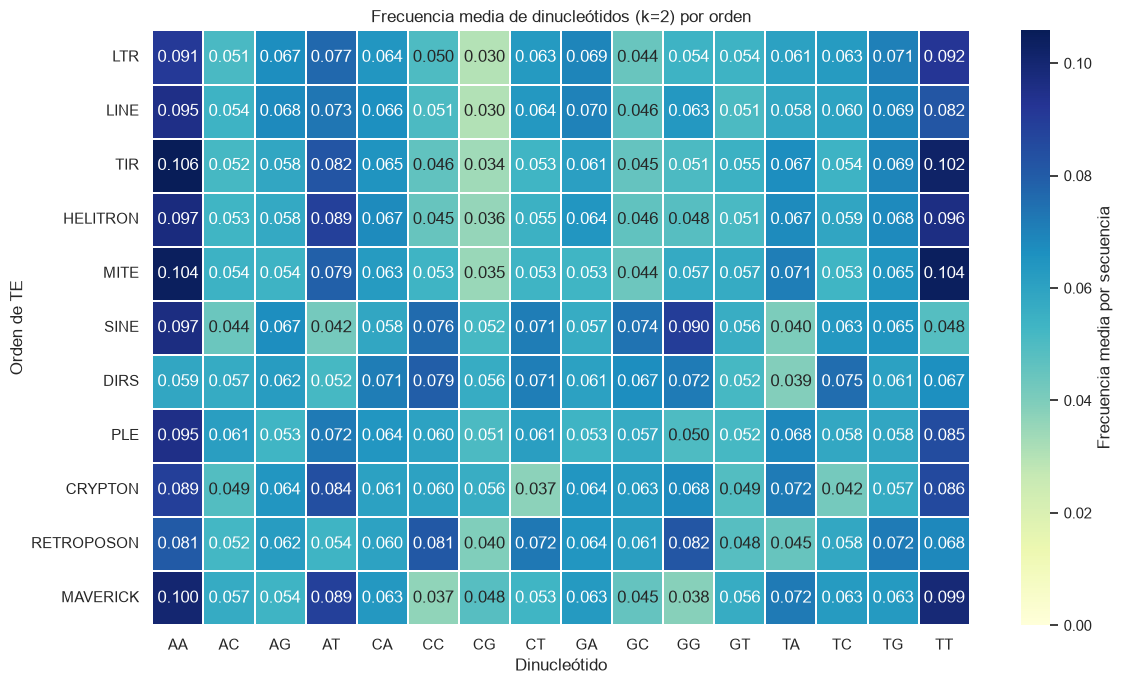

In [15]:
salida_figura_04 = figura_04_dinucleotidos(
    db_analiticas, MODO_PRUEBA_FIGURAS, TAMANO_MUESTRA_FIGURAS
)
datos_figura_04 = pd.DataFrame(salida_figura_04["datos"])
tabla_heatmap = (
    datos_figura_04.pivot_table(
        index="orden", columns="dinucleotido",
        values="frecuencia_promedio", aggfunc="mean"
    )
    .reindex(index=ORDENES_FIGURAS, columns=DINUCLEOTIDOS)
)

figura_04, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(
    tabla_heatmap, mask=tabla_heatmap.isna(), cmap="YlGnBu",
    vmin=0, vmax=float(np.nanmax(tabla_heatmap.to_numpy())),
    annot=True, fmt=".3f", linewidths=0.35, linecolor="white",
    cbar_kws={"label": "Frecuencia media por secuencia"}, ax=ax
)
ax.set_xlabel("Dinucleótido")
ax.set_ylabel("Orden de TE")
ax.set_title("Frecuencia media de dinucleótidos (k=2) por orden")
figura_04.tight_layout()
rutas_figura_04 = guardar_figura(figura_04, "figura_4_heatmap_dinucleotidos")

tabla_muestras_heatmap = (
    datos_figura_04.groupby("orden")["secuencias_validas"]
    .max().reindex(ORDENES_FIGURAS)
)
print("Modo:", salida_figura_04["modo"], "| filas de la matriz:", len(datos_figura_04))
print("Cálculo aplicado: frecuencia por secuencia = count / valid_windows; después se promedia por orden.")
display(tabla_muestras_heatmap.to_frame("secuencias"))
display(figura_04)
plt.close(figura_04)

**Interpretación:** el heatmap permite comparar perfiles relativos de dinucleótidos entre órdenes, independientemente de la longitud individual de cada secuencia. Las celdas representan promedios por secuencia y no conteos globales; por tanto, un orden con más registros no obtiene automáticamente valores mayores. La inclusión explícita de ceros evita sobreestimar dinucleótidos que no aparecen en todas las secuencias.

### Resumen técnico y reproducibilidad

Las cuatro figuras se construyen a partir de resultados de MongoDB y no de valores escritos manualmente. El modo de prueba utiliza 5.000 documentos; el modo final (`MODO_PRUEBA_FIGURAS = False`) recorre la colección completa. Cada figura queda acompañada por su tabla de respaldo y se exporta a `paper/figures/` en formatos PNG (300 dpi) y PDF.